In [26]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
import torch
import os
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import transforms
from PIL import Image

In [37]:
class ImageProcessor :
    def __init__(self, root_dir_path, transformations=None) :
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # list of paths of all images
        self.all_img_paths = [os.path.join(root_dir_path, img) for img in os.listdir(root_dir_path)]

    def __len__(self) :
        return len(self.all_img_paths)

    def __getitem__(self, idx) :
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations :
            img = self.transformations(img)

        return img

In [38]:
root_dir_path = "./img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178), # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # [-1, 1]
])

In [39]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

loaded 202593 images


In [40]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

In [41]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [42]:
class Generator(nn.Module) :
    def __init__(self, z_dim=100, img_channels=3): # 3 is for RGB
        super(Generator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.ReLU(),

            nn.Linear(256, 512),
            nn.ReLU(),

            nn.Linear(512, 1024),
            nn.ReLU(),

            nn.Linear(1024, 64 * 64 * img_channels),
            nn.Tanh(), # [-1, 1]
        )

    def forward(self, z) :
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64)
        return img

In [43]:
class Discriminator (nn.Module) :
    def __init__(self, img_channels=3) :
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            nn.Flatten(), # converts the 4D tensor to 1D

            nn.Linear(img_channels * 64 * 64, 1024),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1),
            nn.Sigmoid(), # prob of being real or fake
        )

    def forward(self, img) :
        return self.model(img)

In [44]:
GAN_loss = nn.BCELoss()

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999)) # these are the standard values

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [47]:
if torch.backends.mps.is_available() :
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else :
    device = torch.device("cpu")
print(device)

cuda


In [48]:
generator = generator.to(device)
discriminator = discriminator.to(device)

In [ ]:
def train(generator, discriminator, dataloader, epochs=5) :
    for epoch in range(epochs):
      for i, imgs in enumerate(dataloader) :
          real_imgs = imgs.to(device)
          batch_size = real_imgs.size(0)

          # create real imgs labels & fake imgs labels
          real_labels = torch.ones(batch_size, 1, device=device) # [1, 1, 1, ....]
          fake_labels = torch.zeros(batch_size, 1, device=device) # [0, 0, 0, ...]

          # Train the discriminator
          d_optimizer.zero_grad()

          fake_imgs = generator(torch.randn(batch_size, 100).to(device))

          real_loss = GAN_loss(discriminator(real_imgs), real_labels)
          fake_loss = GAN_loss(discriminator(fake_imgs), fake_labels)

          d_loss = (real_loss + fake_loss) /2

          d_loss.backward(retain_graph=True)
          d_optimizer.step()

          # Train the Generator
          g_optimizer.zero_grad()

          g_loss = GAN_loss(discriminator(fake_imgs), real_labels)

          g_loss.backward()
          g_optimizer.step()

          if i % 50 == 0 : # for every 50 th batch 
              print(f"for epoch: {epoch+1}/{epochs}... batch: {i+1}... G-loss:{g_loss}... D-loss:{d_loss}")
      # save generated images for each epoch
      save_generated_images(generator, epoch, device)

In [68]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, num_imgs=8) :
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

for epoch: 1/5... batch: 1... G-loss:1.6715919971466064... D-loss:0.4557017683982849
for epoch: 1/5... batch: 51... G-loss:2.1196327209472656... D-loss:0.3834397792816162
for epoch: 1/5... batch: 101... G-loss:2.9641008377075195... D-loss:0.5670480728149414
for epoch: 1/5... batch: 151... G-loss:2.1643314361572266... D-loss:0.4096056818962097
for epoch: 1/5... batch: 201... G-loss:2.1167993545532227... D-loss:0.3316952884197235
for epoch: 1/5... batch: 251... G-loss:2.073016881942749... D-loss:0.3558162450790405
for epoch: 1/5... batch: 301... G-loss:1.9213557243347168... D-loss:0.31641584634780884
for epoch: 1/5... batch: 351... G-loss:1.9649217128753662... D-loss:0.8697445392608643
for epoch: 1/5... batch: 401... G-loss:2.2428622245788574... D-loss:0.521599292755127
for epoch: 1/5... batch: 451... G-loss:2.214365005493164... D-loss:0.41571033000946045
for epoch: 1/5... batch: 501... G-loss:2.0060083866119385... D-loss:0.48794716596603394
for epoch: 1/5... batch: 551... G-loss:2.38990

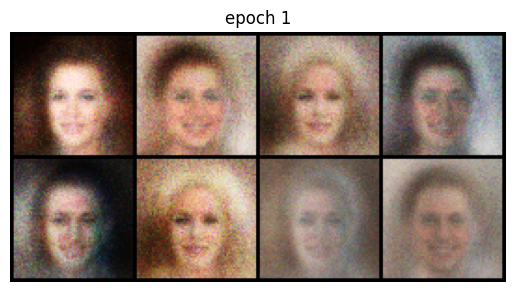

for epoch: 2/5... batch: 1... G-loss:1.9684964418411255... D-loss:0.43121886253356934
for epoch: 2/5... batch: 51... G-loss:2.358686923980713... D-loss:0.41111594438552856
for epoch: 2/5... batch: 101... G-loss:1.995944857597351... D-loss:0.38923102617263794
for epoch: 2/5... batch: 151... G-loss:2.0643038749694824... D-loss:0.5559021234512329
for epoch: 2/5... batch: 201... G-loss:1.8954651355743408... D-loss:0.43483227491378784
for epoch: 2/5... batch: 251... G-loss:2.405014753341675... D-loss:0.4272110164165497
for epoch: 2/5... batch: 301... G-loss:2.3627541065216064... D-loss:0.4359756112098694
for epoch: 2/5... batch: 351... G-loss:1.8239611387252808... D-loss:0.4834773540496826
for epoch: 2/5... batch: 401... G-loss:2.280487537384033... D-loss:0.6094960570335388
for epoch: 2/5... batch: 451... G-loss:1.6369805335998535... D-loss:0.5053684711456299
for epoch: 2/5... batch: 501... G-loss:1.8080730438232422... D-loss:0.4735071659088135
for epoch: 2/5... batch: 551... G-loss:2.76995

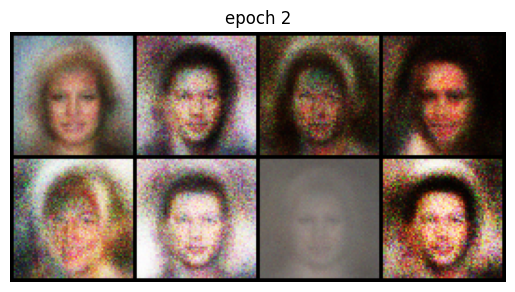

for epoch: 3/5... batch: 1... G-loss:1.5242472887039185... D-loss:0.5154762268066406
for epoch: 3/5... batch: 51... G-loss:1.3125865459442139... D-loss:0.5368434190750122
for epoch: 3/5... batch: 101... G-loss:1.5263562202453613... D-loss:0.4585246443748474
for epoch: 3/5... batch: 151... G-loss:1.6770761013031006... D-loss:0.46022701263427734
for epoch: 3/5... batch: 201... G-loss:1.9038796424865723... D-loss:0.5343608856201172
for epoch: 3/5... batch: 251... G-loss:1.5325236320495605... D-loss:0.5385948419570923
for epoch: 3/5... batch: 301... G-loss:1.6928040981292725... D-loss:0.49855291843414307
for epoch: 3/5... batch: 351... G-loss:1.7211098670959473... D-loss:0.5058750510215759
for epoch: 3/5... batch: 401... G-loss:2.1695683002471924... D-loss:0.46653902530670166
for epoch: 3/5... batch: 451... G-loss:1.6776012182235718... D-loss:0.47927260398864746
for epoch: 3/5... batch: 501... G-loss:1.844743013381958... D-loss:0.49206769466400146
for epoch: 3/5... batch: 551... G-loss:1.3

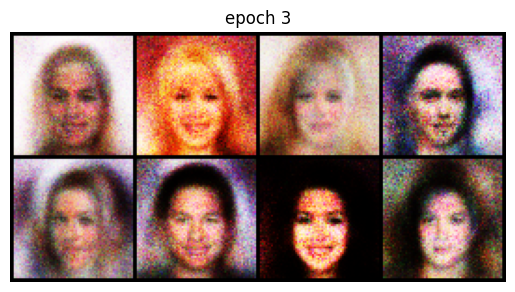

for epoch: 4/5... batch: 1... G-loss:1.8017606735229492... D-loss:0.4885998070240021
for epoch: 4/5... batch: 51... G-loss:1.3714369535446167... D-loss:0.5560270547866821
for epoch: 4/5... batch: 101... G-loss:1.421766996383667... D-loss:0.61319899559021
for epoch: 4/5... batch: 151... G-loss:1.6594356298446655... D-loss:0.46122777462005615
for epoch: 4/5... batch: 201... G-loss:1.5282933712005615... D-loss:0.46879690885543823
for epoch: 4/5... batch: 251... G-loss:1.6414185762405396... D-loss:0.5101698040962219
for epoch: 4/5... batch: 301... G-loss:1.603371500968933... D-loss:0.575693666934967
for epoch: 4/5... batch: 351... G-loss:1.5319714546203613... D-loss:0.5884453654289246
for epoch: 4/5... batch: 401... G-loss:1.4451014995574951... D-loss:0.5319086313247681
for epoch: 4/5... batch: 451... G-loss:1.5563368797302246... D-loss:0.49215224385261536
for epoch: 4/5... batch: 501... G-loss:1.734710693359375... D-loss:0.5217577219009399
for epoch: 4/5... batch: 551... G-loss:1.73957848

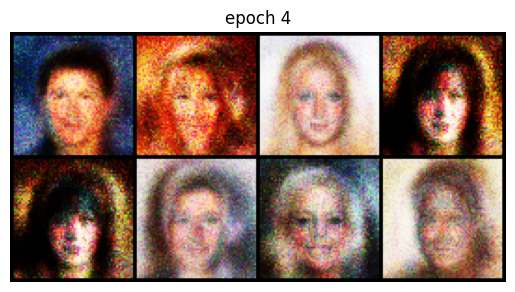

for epoch: 5/5... batch: 1... G-loss:1.4860687255859375... D-loss:0.5401023626327515
for epoch: 5/5... batch: 51... G-loss:1.5226081609725952... D-loss:0.49352961778640747
for epoch: 5/5... batch: 101... G-loss:1.5928840637207031... D-loss:0.45123231410980225
for epoch: 5/5... batch: 151... G-loss:1.1931049823760986... D-loss:0.5817275047302246
for epoch: 5/5... batch: 201... G-loss:1.5116430521011353... D-loss:0.5639710426330566
for epoch: 5/5... batch: 251... G-loss:1.3666257858276367... D-loss:0.5202807188034058
for epoch: 5/5... batch: 301... G-loss:1.4967169761657715... D-loss:0.5497234463691711
for epoch: 5/5... batch: 351... G-loss:1.4131194353103638... D-loss:0.47374773025512695
for epoch: 5/5... batch: 401... G-loss:1.6865190267562866... D-loss:0.5031293630599976
for epoch: 5/5... batch: 451... G-loss:1.305769920349121... D-loss:0.5943344235420227
for epoch: 5/5... batch: 501... G-loss:1.5862704515457153... D-loss:0.5756739377975464
for epoch: 5/5... batch: 551... G-loss:1.386

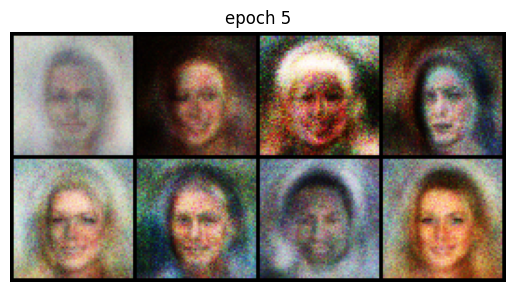

In [69]:
train(generator, discriminator, dataloader, epochs=5)